# BEPAD: train a model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/03_train.ipynb)

A standard PyTorch training loop on a small part of BEPAD: a network that learns whether **two
picks belong to the same earthquake**, from their time difference, station distance and phases,
the building block of many learned associators. About 2 minutes on a CPU. Documentation:
[Train a model](https://bepad.readthedocs.io/en/latest/train.html).

In [ ]:
%pip install -q "bepad>=0.1.2"
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"     # quieter downloads

## 1. Data

[`ReleaseWindowDataset`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.torch.ReleaseWindowDataset) gives the released windows of a
split; each one is read from disk when the `DataLoader` asks for it, so memory stays small.
[`collate_windows`](https://bepad.readthedocs.io/en/latest/reference/api.html#bepad.torch.collate_windows) puts several windows into one batch
(`pick_batch` says which window each pick is from). Here: 300 Texas train windows, 100 val windows.

In [ ]:
import torch
from torch.utils.data import DataLoader
from bepad.torch import ReleaseWindowDataset, collate_windows

train = ReleaseWindowDataset(split="train", networks=["tx"], max_windows=300)
val = ReleaseWindowDataset(split="val", networks=["tx"], max_windows=100)
loader = DataLoader(train, batch_size=16, shuffle=True, collate_fn=collate_windows)
val_loader = DataLoader(val, batch_size=16, collate_fn=collate_windows)

batch = next(iter(loader))
{k: tuple(v.shape) for k, v in batch.items() if torch.is_tensor(v)}

{'station_coords': (5072, 3),
 'pick_station': (6504,),
 'pick_phase': (6504,),
 'pick_time': (6504,),
 'pick_label': (6504,),
 'pick_prob': (6504,),
 'pick_real': (6504,),
 'pick_type': (6504,),
 'pick_sigma': (6504,),
 'pick_scorable': (6504,),
 'event_origin': (101, 4),
 'event_scorable': (101,),
 'pick_batch': (6504,),
 'station_batch': (5072,),
 'event_batch': (101,)}

`pick_label` is the earthquake of each pick in its window (−1 = noise), `pick_time` its time
in seconds, `pick_station` its row in `station_coords` (latitude, longitude, elevation). All keys:
[Train a model](https://bepad.readthedocs.io/en/latest/train.html#all-batch-keys).

## 2. Training examples: pairs of picks

From each window, draw random pairs of picks. Features: time difference, distance between the two
stations, same phase, P with S. Label: 1 if both picks are from the same earthquake.

In [ ]:
def pairs(batch, n=512, gen=None):
    feats, labels = [], []
    xyz = batch["station_coords"]
    for k in batch["pick_batch"].unique():
        idx = torch.nonzero(batch["pick_batch"] == k).squeeze(1)          # the picks of window k
        a = idx[torch.randint(len(idx), (n,), generator=gen)]
        b = idx[torch.randint(len(idx), (n,), generator=gen)]
        sa, sb = xyz[batch["pick_station"][a]], xyz[batch["pick_station"][b]]
        lat = torch.deg2rad((sa[:, 0] + sb[:, 0]) / 2)
        dist = torch.hypot((sa[:, 1] - sb[:, 1]) * 111.2 * torch.cos(lat), (sa[:, 0] - sb[:, 0]) * 111.2)   # km
        dt = (batch["pick_time"][a] - batch["pick_time"][b]).abs()                                         # s
        pa, pb = batch["pick_phase"][a], batch["pick_phase"][b]                                            # 0 P, 1 S
        feats.append(torch.stack([dt / 10, dist / 100, (pa == pb).float(), (pa + pb == 1).float()], 1))
        la, lb = batch["pick_label"][a], batch["pick_label"][b]
        labels.append(((la == lb) & (la >= 0)).float())                   # same earthquake, not noise
    return torch.cat(feats), torch.cat(labels)

## 3. Train

A small network (multilayer perceptron), the usual loop: forward, loss, backward, step; then the
accuracy on the validation pairs after each epoch.

In [ ]:
from torch import nn

torch.manual_seed(0)
model = nn.Sequential(nn.Linear(4, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

def val_accuracy():
    gen, right, total = torch.Generator().manual_seed(0), 0, 0
    with torch.no_grad():
        for batch in val_loader:
            x, y = pairs(batch, gen=gen)
            right += ((torch.sigmoid(model(x).squeeze(1)) > 0.5) == (y > 0.5)).sum().item()
            total += len(y)
    return right / total

history = []
for epoch in range(5):
    total = 0
    for batch in loader:
        x, y = pairs(batch)
        loss = loss_fn(model(x).squeeze(1), y)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    history.append({"epoch": epoch + 1, "train loss": total / len(loader), "val accuracy": val_accuracy()})
    print(history[-1])

{'epoch': 1, 'train loss': 0.5048904560114208, 'val accuracy': 0.848203125}


{'epoch': 2, 'train loss': 0.30026446596572276, 'val accuracy': 0.848203125}


{'epoch': 3, 'train loss': 0.25623560108636556, 'val accuracy': 0.8867578125}


{'epoch': 4, 'train loss': 0.2331552505493164, 'val accuracy': 0.90833984375}


{'epoch': 5, 'train loss': 0.22008373470682846, 'val accuracy': 0.9080078125}


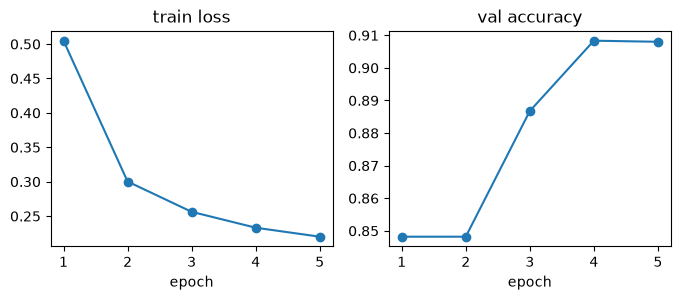

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

h = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
h["train loss"].plot(ax=axes[0], marker="o", title="train loss")
h["val accuracy"].plot(ax=axes[1], marker="o", title="val accuracy");

## 4. What did it learn?

The probability that two P picks are from the same earthquake, for each time difference and
distance between their stations. Picks close in time at nearby stations are most likely from the
same earthquake; the probability falls as the time difference or the distance grows.

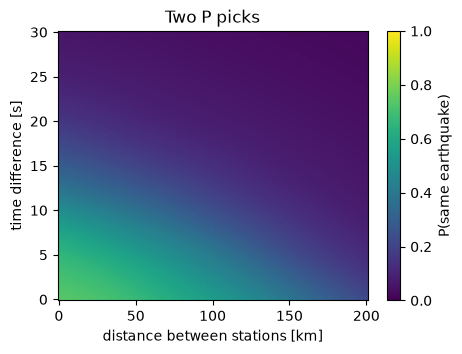

In [ ]:
import numpy as np

dts, dists = np.linspace(0, 30, 120), np.linspace(0, 200, 120)
D, T = np.meshgrid(dists, dts)
x = torch.tensor(np.c_[T.ravel() / 10, D.ravel() / 100, np.ones(T.size), np.zeros(T.size)], dtype=torch.float32)
with torch.no_grad():
    p = torch.sigmoid(model(x)).reshape(T.shape).numpy()

fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.pcolormesh(D, T, p, vmin=0, vmax=1, cmap="viridis")
fig.colorbar(im, label="P(same earthquake)")
ax.set(xlabel="distance between stations [km]", ylabel="time difference [s]", title="Two P picks");

## Next

* Train on more networks: change `networks` (or leave it out for every network, a 26 GB download)
  and `max_windows`; choose windows by their metadata: [Choose windows](https://bepad.readthedocs.io/en/latest/get_data.html#choose-windows).
* `prob` (a soft label, ≥ 0.5 for arrivals) and generated windows from the pool for more data:
  [Train a model](https://bepad.readthedocs.io/en/latest/train.html).
* To score a trained model, wrap it in an associator: [Benchmark your associator](https://colab.research.google.com/github/ecastillot/BEPAD/blob/main/notebooks/02_benchmark.ipynb).